# Task 2: Feature engineering and model comparison with cross-validation
Goal: compare LogisticRegression, LinearSVC, MultinomialNB and RandomForest on TF-IDF features using 5-fold cross-validation, pick the best by **macro-F1**, plot its confusion matrix, and save it as `best_classifier.pkl`.

Cross-validation runs on the **training split only**. The test split is used once, at the end.

In [1]:
import re, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

## 1. Load and clean the data (same steps and same split as Task 1)

In [2]:
DATA_PATH = "data/tickets.csv"
TEXT_COL  = "instruction"
LABEL_COL = "category"

def clean(t):
    t = str(t).lower()
    t = re.sub(r"http\S+", " ", t)
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df = pd.read_csv(DATA_PATH)
df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates()
df["text"] = df[TEXT_COL].apply(clean)
df = df[df["text"].str.len() > 0]
print(df.shape)

X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df[LABEL_COL], test_size=0.2, random_state=42, stratify=df[LABEL_COL])
print(len(X_train), len(X_test))

(24635, 3)
19708 4927


## 2. Build one pipeline per model
Every pipeline contains its own TF-IDF vectorizer, so inside cross-validation the vectorizer is fit on the training folds only (no leakage).
The last model is a feature-engineering variant: word TF-IDF **plus** character n-grams, which should help with typos like "pyment".

In [3]:
def word_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, stop_words="english")

def word_char_tfidf():
    return FeatureUnion([
        ("word", word_tfidf()),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2)),
    ])

models = {
    "LogisticRegression": Pipeline([("tfidf", word_tfidf()), ("clf", LogisticRegression(max_iter=1000))]),
    "LinearSVC":          Pipeline([("tfidf", word_tfidf()), ("clf", LinearSVC())]),
    "MultinomialNB":      Pipeline([("tfidf", word_tfidf()), ("clf", MultinomialNB())]),
    "RandomForest":       Pipeline([("tfidf", word_tfidf()), ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42))]),
    "LinearSVC + char n-grams": Pipeline([("tfidf", word_char_tfidf()), ("clf", LinearSVC())]),
}
list(models)

['LogisticRegression',
 'LinearSVC',
 'MultinomialNB',
 'RandomForest',
 'LinearSVC + char n-grams']

## 3. 5-fold stratified cross-validation (macro-F1)
RandomForest and the char n-gram model are the slowest. This cell can take a few minutes.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"macro_f1": "f1_macro", "accuracy": "accuracy"}

rows = []
for name, pipe in models.items():
    t0 = time.time()
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "macro_F1_mean": res["test_macro_f1"].mean(),
        "macro_F1_std": res["test_macro_f1"].std(),
        "accuracy_mean": res["test_accuracy"].mean(),
        "seconds": time.time() - t0,
    })
    print(f"{name:28s} macro-F1 = {rows[-1]['macro_F1_mean']:.4f} (+/- {rows[-1]['macro_F1_std']:.4f})")

LogisticRegression           macro-F1 = 0.9959 (+/- 0.0007)
LinearSVC                    macro-F1 = 0.9968 (+/- 0.0004)
MultinomialNB                macro-F1 = 0.9961 (+/- 0.0005)
RandomForest                 macro-F1 = 0.9943 (+/- 0.0007)
LinearSVC + char n-grams     macro-F1 = 0.9999 (+/- 0.0001)


## 4. Comparison table and chart

In [5]:
results = pd.DataFrame(rows).sort_values("macro_F1_mean", ascending=False).reset_index(drop=True)
results.to_csv("model_comparison.csv", index=False)
results.round(4)

,model,macro_F1_mean,macro_F1_std,accuracy_mean,seconds
0,LinearSVC + char n-grams,0.9999,0.0001,0.9999,79.6443
1,LinearSVC,0.9968,0.0004,0.9970,11.5163
2,MultinomialNB,0.9961,0.0005,0.9958,7.1200
3,LogisticRegression,0.9959,0.0007,0.9958,16.0767
4,RandomForest,0.9943,0.0007,0.9947,28.8251


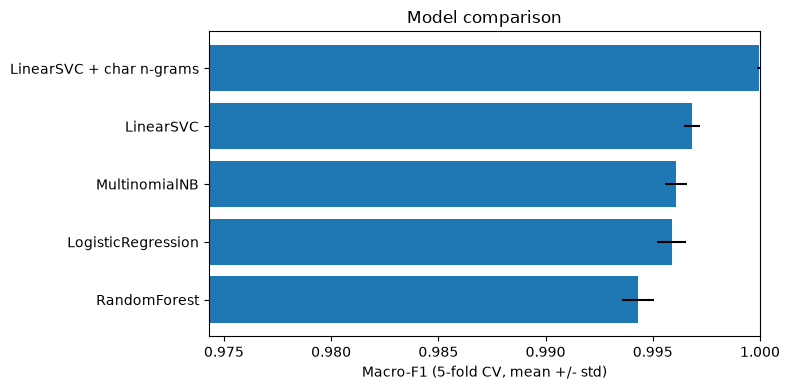

In [6]:
plt.figure(figsize=(8, 4))
plt.barh(results["model"][::-1], results["macro_F1_mean"][::-1], xerr=results["macro_F1_std"][::-1])
plt.xlabel("Macro-F1 (5-fold CV, mean +/- std)")
plt.xlim(results["macro_F1_mean"].min() - 0.02, 1.0)
plt.title("Model comparison")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

## 5. Select the best model and fit it on the full training split

In [7]:
best_name = results.loc[0, "model"]
print("Best model by CV macro-F1:", best_name)

best_model = clone(models[best_name])
best_model.fit(X_train, y_train)

Best model by CV macro-F1: LinearSVC + char n-grams


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](11,)","['ACCOUNT','CANCEL','CONTACT',...,'REFUND','SHIPPING','SUBSCRIPTION']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word', ...), ('char', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


## 6. Evaluate once on the held-out test split

In [8]:
pred = best_model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, pred):.2%}")
print(f"Test macro-F1: {f1_score(y_test, pred, average='macro'):.4f}")
print(classification_report(y_test, pred))

Test accuracy: 99.96%
Test macro-F1: 0.9995
              precision    recall  f1-score   support

     ACCOUNT       1.00      1.00      1.00      1088
      CANCEL       1.00      1.00      1.00       190
     CONTACT       1.00      1.00      1.00       400
    DELIVERY       0.99      1.00      1.00       332
    FEEDBACK       1.00      1.00      1.00       399
     INVOICE       1.00      1.00      1.00       366
       ORDER       1.00      1.00      1.00       634
     PAYMENT       1.00      1.00      1.00       400
      REFUND       1.00      1.00      1.00       524
    SHIPPING       1.00      1.00      1.00       394
SUBSCRIPTION       1.00      1.00      1.00       200

    accuracy                           1.00      4927
   macro avg       1.00      1.00      1.00      4927
weighted avg       1.00      1.00      1.00      4927



## 7. Confusion matrix (plotted and saved)

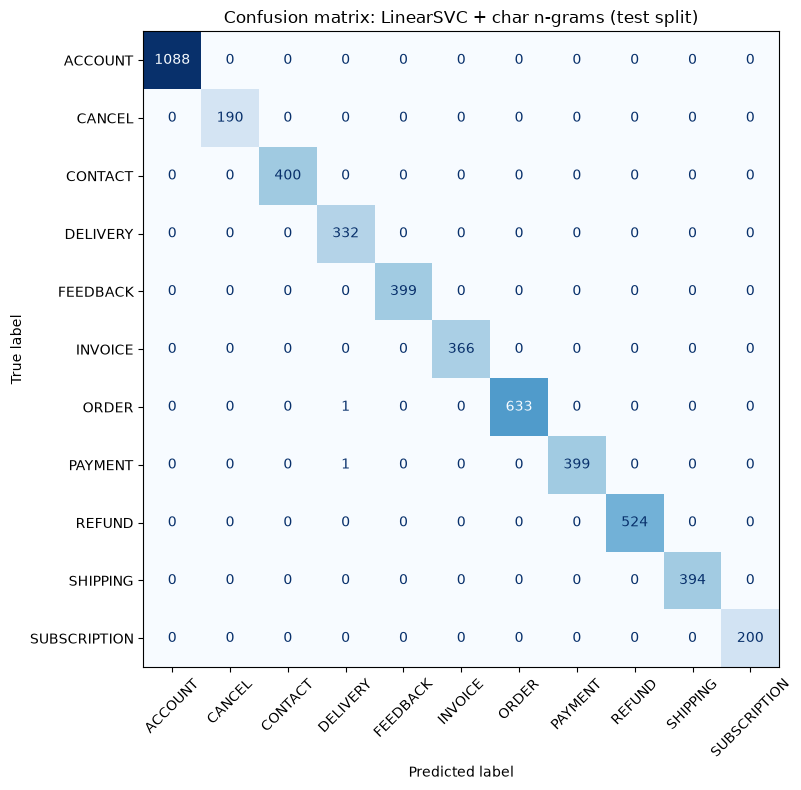

In [9]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix: {best_name} (test split)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [10]:
wrong = pd.DataFrame({"text": X_test.values, "true": y_test.values, "pred": pred})
wrong = wrong[wrong["true"] != wrong["pred"]]
print(len(wrong), "errors")
wrong

2 errors


,text,true,pred
2775,i dont know how i can check the eta of my last...,ORDER,DELIVERY
2825,i get an error when i try to check out,PAYMENT,DELIVERY


## 8. Save the best model

In [11]:
with open("best_classifier.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open("best_classifier.pkl", "rb") as f:
    loaded_best = pickle.load(f)
print(loaded_best.predict([clean("I want a refund for my cancelled booking")]))

['REFUND']


## 9. Re-test the hard tickets from Task 1
Typos and the praise ticket that the baseline got wrong. Predictions only (the best model may not expose probabilities).

In [12]:
hard = [
    "i want my reimbursment",
    "my pyment did not go thru",
    "cant chnage my adress",
    "unsubcribe me plz",
    "Thanks, great service!",
    "I can't pay with my card",
]
for t in hard:
    print(f"{t:35s} -> {loaded_best.predict([clean(t)])[0]}")

i want my reimbursment              -> REFUND
my pyment did not go thru           -> PAYMENT
cant chnage my adress               -> SHIPPING
unsubcribe me plz                   -> SUBSCRIPTION
Thanks, great service!              -> CONTACT
I can't pay with my card            -> PAYMENT


## Notes
- **Method:** Models were compared with 5-fold stratified cross-validation on the training split only (TF-IDF vectorizer inside each pipeline, so no leakage). The test split was used once, for the chosen model.
- **Which model won:** LinearSVC with word + character n-gram TF-IDF, with a CV macro-F1 of 0.9999 (std 0.0001). Of the four required models, LinearSVC was best (0.9968), then MultinomialNB (0.9961), LogisticRegression (0.9959) and RandomForest (0.9943).
- **Did character n-grams help?** Yes. They added about 0.003 macro-F1 over plain LinearSVC, more than the fold-to-fold std, and they fixed all 4 of my hand-written typo tickets ("pyment", "reimbursment", "chnage my adress", "unsubcribe"). The Task 1 baseline got 1 of 4.
- **Test result:** 99.96% accuracy and 0.9995 macro-F1 on the held-out test split.
- **The two remaining errors:** both were predicted as DELIVERY. One is an ORDER ticket asking about the ETA of a last order, and the other is a PAYMENT ticket about an error at checkout. Both were also baseline errors, and both are arguably ambiguous between categories.
- **Still wrong:** "Thanks, great service!" is predicted as CONTACT instead of FEEDBACK, because none of the 24,635 tickets contain praise wording. Character n-grams cannot fix missing data.
- **Limits:** The dataset is synthetic and templated (including its typos), so 99.96% is near the ceiling and some of the gain may come from near-duplicate matching. Real tickets will likely score lower. A grouped split by near-duplicate cluster is not done.
  